#1. Import Libraries

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pyarrow.parquet as pq

from pathlib import Path

sns.set_theme(style="whitegrid")

#2. Load Dataset and Check Dimensions

In [3]:
# Locate the existing dataset
possible_paths = [
    Path("data/india_air_quality.parquet"),
    Path("IndianAirQualityEDA/data/india_air_quality.parquet")
]

file_path = next((path for path in possible_paths if path.exists()), None)

if file_path is None:
    raise FileNotFoundError(
        "Place this notebook inside IndianAirQualityEDA, "
        "or extract the original ZIP file first."
    )

# Read dataset metadata without loading the complete file
parquet_file = pq.ParquetFile(file_path)

print("Total Records:", parquet_file.metadata.num_rows)
print("Total Attributes:", len(parquet_file.schema_arrow.names))
print("Attributes:", parquet_file.schema_arrow.names)

Total Records: 19588151
Total Attributes: 5
Attributes: ['station_id', 'parameter_name', 'unit', 'collected_at', 'value']


#3. Prepare a 100,000+ Record Sample

In [4]:
# Read the data in batches and keep a sample from each batch
sample_parts = []
batch_number = 0

columns = ["station_id", "parameter_name", "unit", "collected_at", "value"]

for batch in parquet_file.iter_batches(batch_size=100000, columns=columns):

    chunk = batch.to_pandas()

    chunk["value"] = pd.to_numeric(chunk["value"], errors="coerce")
    chunk["collected_at"] = pd.to_datetime(
        chunk["collected_at"], errors="coerce", utc=True
    )

    chunk.dropna(subset=["station_id", "parameter_name", "collected_at", "value"], inplace=True)

    # Keep up to 1,000 records from each batch
    if len(chunk) > 0:
        sample_parts.append(
            chunk.sample(n=min(1000, len(chunk)), random_state=42 + batch_number)
        )

    batch_number += 1

sample_df = pd.concat(sample_parts, ignore_index=True)

# Limit the final sample to 150,000 records for faster plotting
if len(sample_df) > 150000:
    sample_df = sample_df.sample(n=150000, random_state=42)

# Standardize pollutant names (example: PM2.5 becomes PM25)
sample_df["parameter_name"] = (
    sample_df["parameter_name"]
    .astype(str)
    .str.upper()
    .str.replace(".", "", regex=False)
)

sample_df["station_id"] = sample_df["station_id"].astype(str)

print("Full Dataset Records:", parquet_file.metadata.num_rows)
print("Visualization Sample Shape:", sample_df.shape)
print("Pollutants:", sample_df["parameter_name"].nunique())
print("Stations:", sample_df["station_id"].nunique())

if len(sample_df) < 100000:
    print("Warning: The cleaned sample contains fewer than 100,000 records.")

Full Dataset Records: 19588151
Visualization Sample Shape: (150000, 5)
Pollutants: 5
Stations: 533


#4. Select a Pollutant for Visualization

In [5]:
# Use PM2.5 when available; otherwise use the most common pollutant
pollutant_counts = sample_df["parameter_name"].value_counts()

if "PM25" in pollutant_counts.index:
    selected_pollutant = "PM25"
else:
    selected_pollutant = pollutant_counts.index[0]

pollutant_df = sample_df[
    sample_df["parameter_name"] == selected_pollutant
].copy()

print("Selected Pollutant:", selected_pollutant)
print("Observations:", len(pollutant_df))
print("Unit:", pollutant_df["unit"].mode().iloc[0])

Selected Pollutant: PM25
Observations: 30045
Unit: µg/m³


#5. Scatter Plot – Measurement Over Time

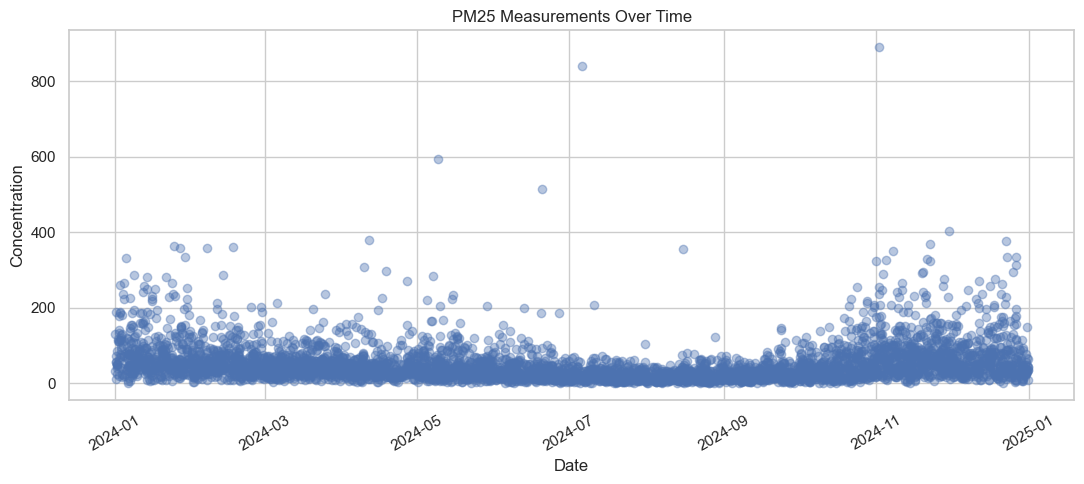

In [6]:
# Use a smaller sample so the scatter plot remains readable
scatter_df = pollutant_df.sample(
    n=min(5000, len(pollutant_df)), random_state=42
)

plt.figure(figsize=(11, 5))
plt.scatter(scatter_df["collected_at"], scatter_df["value"], alpha=0.4)
plt.title(f"{selected_pollutant} Measurements Over Time")
plt.xlabel("Date")
plt.ylabel("Concentration")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

#6. Box Plot – Distribution and Outliers

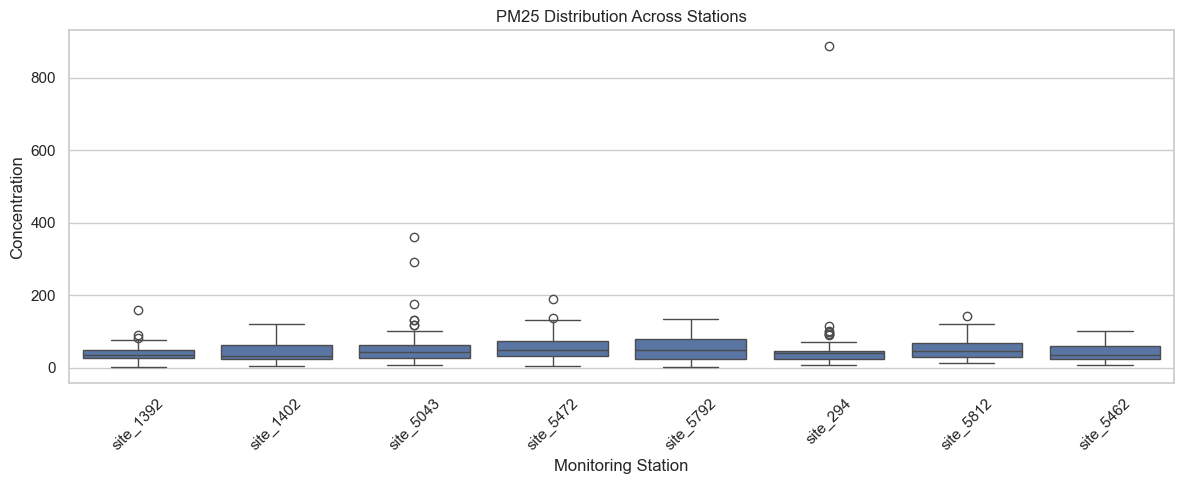

Lower Bound: -43.22
Upper Bound: 125.54
Outlier Observations: 1896


In [7]:
# Select the 8 stations with the most observations for this pollutant
top_stations = pollutant_df["station_id"].value_counts().head(8).index
box_df = pollutant_df[pollutant_df["station_id"].isin(top_stations)]

plt.figure(figsize=(12, 5))
sns.boxplot(data=box_df, x="station_id", y="value", showfliers=True)
plt.title(f"{selected_pollutant} Distribution Across Stations")
plt.xlabel("Monitoring Station")
plt.ylabel("Concentration")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Identify outliers using the IQR method
q1 = pollutant_df["value"].quantile(0.25)
q3 = pollutant_df["value"].quantile(0.75)
iqr = q3 - q1
lower_limit = q1 - 1.5 * iqr
upper_limit = q3 + 1.5 * iqr

outliers = pollutant_df[
    (pollutant_df["value"] < lower_limit) |
    (pollutant_df["value"] > upper_limit)
]

print("Lower Bound:", round(lower_limit, 2))
print("Upper Bound:", round(upper_limit, 2))
print("Outlier Observations:", len(outliers))

#7. Violin Plot – Distribution Shape

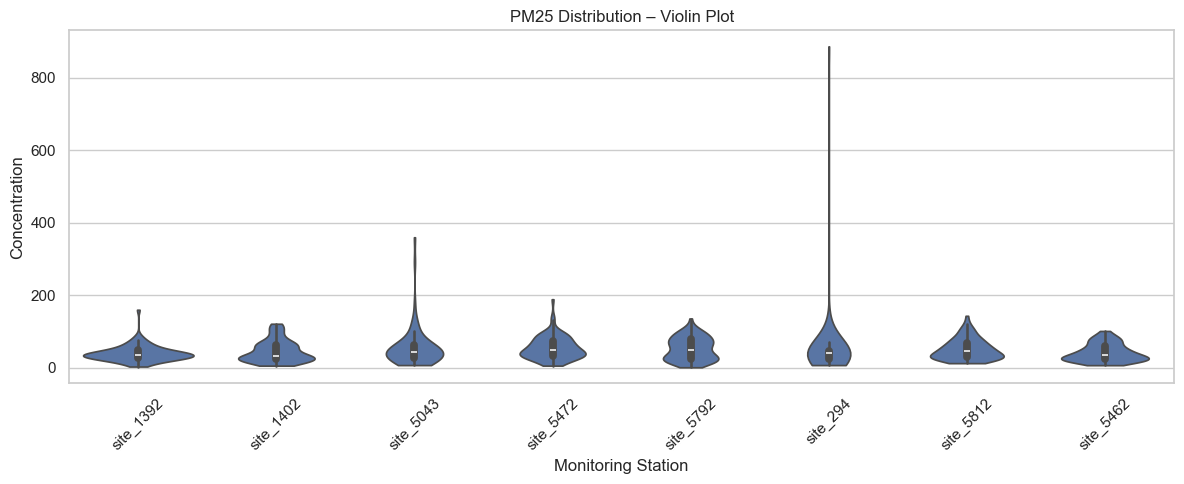

In [8]:
plt.figure(figsize=(12, 5))
sns.violinplot(data=box_df, x="station_id", y="value", cut=0)
plt.title(f"{selected_pollutant} Distribution – Violin Plot")
plt.xlabel("Monitoring Station")
plt.ylabel("Concentration")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

#8. Interactive Filtering